#**1 — Judul dan identitas**



# ANALISIS VISUALISASI DATA KESEHATAN TIDUR DAN GAYA HIDUP

**Nama:** Bonivasius Adiya Dalung  
**NIM:** 2218041  
**Mata Kuliah:** Data Mining  
**Pertemuan:** 6 — Data Visualization  

## Deskripsi Proyek

Proyek ini bertujuan untuk mengeksplorasi dataset Sleep Health and Lifestyle menggunakan Python. Analisis dilakukan melalui beberapa teknik visualisasi untuk memahami distribusi data, membandingkan kelompok, serta mengamati hubungan antarvariabel yang berkaitan dengan tidur dan gaya hidup.

## Tools yang Digunakan

- Google Colab
- Python
- Pandas
- Matplotlib
- Seaborn

## Tujuan Analisis

1. Memahami karakteristik dataset.
2. Menampilkan distribusi variabel numerik.
3. Membandingkan kualitas dan durasi tidur antar kelompok.
4. Mengamati hubungan antarvariabel numerik.
5. Menyusun insight dan kesimpulan berdasarkan hasil visualisasi.


#**2 — Import library**

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Mengatur tampilan visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

print("Library berhasil diimpor.")


Library berhasil diimpor.


#**3 — Membaca dataset**

In [2]:

from pathlib import Path

nama_file = "Sleep_health_and_lifestyle_dataset.csv"
path_file = Path("/content") / nama_file

if not path_file.exists():
    raise FileNotFoundError(
        f"File {nama_file} tidak ditemukan. "
        "Silakan unggah melalui panel Files di sebelah kiri."
    )

df = pd.read_csv(path_file)

# Membersihkan spasi pada nama kolom
df.columns = df.columns.str.strip()

print("Dataset berhasil dibaca!")
print("Jumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])

display(df.head())


Dataset berhasil dibaca!
Jumlah baris: 374
Jumlah kolom: 13


,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


#**4 — Memahami struktur dataset**

In [3]:

print("INFORMASI DATASET")
df.info()

print("\nUKURAN DATASET")
print(f"{df.shape[0]} baris dan {df.shape[1]} kolom")

print("\nNAMA KOLOM")
print(df.columns.tolist())

print("\nSTATISTIK DESKRIPTIF")
display(df.describe(include="all").T)


INFORMASI DATASET
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person ID                374 non-null    int64  
 1   Gender                   374 non-null    object 
 2   Age                      374 non-null    int64  
 3   Occupation               374 non-null    object 
 4   Sleep Duration           374 non-null    float64
 5   Quality of Sleep         374 non-null    int64  
 6   Physical Activity Level  374 non-null    int64  
 7   Stress Level             374 non-null    int64  
 8   BMI Category             374 non-null    object 
 9   Blood Pressure           374 non-null    object 
 10  Heart Rate               374 non-null    int64  
 11  Daily Steps              374 non-null    int64  
 12  Sleep Disorder           155 non-null    object 
dtypes: float64(1), int64(7), object(5)
memory usage: 38.1+ KB

UKU

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Person ID,374.0,NaN,NaN,NaN,187.5,108.108742,1.0,94.25,187.5,280.75,374.0
Gender,374,2,Male,189,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,374.0,NaN,NaN,NaN,42.184492,8.673133,27.0,35.25,43.0,50.0,59.0
Occupation,374,11,Nurse,73,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sleep Duration,374.0,NaN,NaN,NaN,7.132086,0.795657,5.8,6.4,7.2,7.8,8.5
Quality of Sleep,374.0,NaN,NaN,NaN,7.312834,1.196956,4.0,6.0,7.0,8.0,9.0
Physical Activity Level,374.0,NaN,NaN,NaN,59.171123,20.830804,30.0,45.0,60.0,75.0,90.0
Stress Level,374.0,NaN,NaN,NaN,5.385027,1.774526,3.0,4.0,5.0,7.0,8.0
BMI Category,374,4,Normal,195,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Blood Pressure,374,25,130/85,99,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#**5 — Memeriksa kualitas data**

In [4]:

print("JUMLAH NILAI KOSONG PER KOLOM")
display(df.isnull().sum().to_frame("Jumlah Nilai Kosong"))

print("\nJUMLAH BARIS DUPLIKAT")
print(df.duplicated().sum())

print("\nJUMLAH NILAI UNIK PER KOLOM")
display(df.nunique().to_frame("Jumlah Nilai Unik"))


JUMLAH NILAI KOSONG PER KOLOM


,Jumlah Nilai Kosong
Person ID,0
Gender,0
Age,0
Occupation,0
Sleep Duration,0
Quality of Sleep,0
Physical Activity Level,0
Stress Level,0
BMI Category,0
Blood Pressure,0



JUMLAH BARIS DUPLIKAT
0

JUMLAH NILAI UNIK PER KOLOM


,Jumlah Nilai Unik
Person ID,374
Gender,2
Age,31
Occupation,11
Sleep Duration,27
Quality of Sleep,6
Physical Activity Level,16
Stress Level,6
BMI Category,4
Blood Pressure,25


## 6. Visualisasi Data



#**6.1 — Menyiapkan variabel analisis**

In [5]:

# Kolom numerik yang digunakan dalam analisis
kolom_numerik = [
    "Age",
    "Sleep Duration",
    "Quality of Sleep",
    "Physical Activity Level",
    "Stress Level",
    "Heart Rate",
    "Daily Steps"
]

# Memastikan kolom yang diperlukan tersedia
kolom_tidak_ada = [
    kolom for kolom in kolom_numerik
    if kolom not in df.columns
]

if kolom_tidak_ada:
    raise ValueError(
        f"Kolom berikut tidak ditemukan: {kolom_tidak_ada}"
    )

# Mengubah kolom analisis menjadi numerik jika diperlukan
for kolom in kolom_numerik:
    df[kolom] = pd.to_numeric(df[kolom], errors="coerce")

print("Variabel analisis siap digunakan.")
display(df[kolom_numerik].head())


Variabel analisis siap digunakan.


,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps
0,27,6.1,6,42,6,77,4200
1,28,6.2,6,60,8,75,10000
2,28,6.2,6,60,8,75,10000
3,28,5.9,4,30,8,85,3000
4,28,5.9,4,30,8,85,3000


### 6.2 Histogram — Distribusi Durasi Tidur

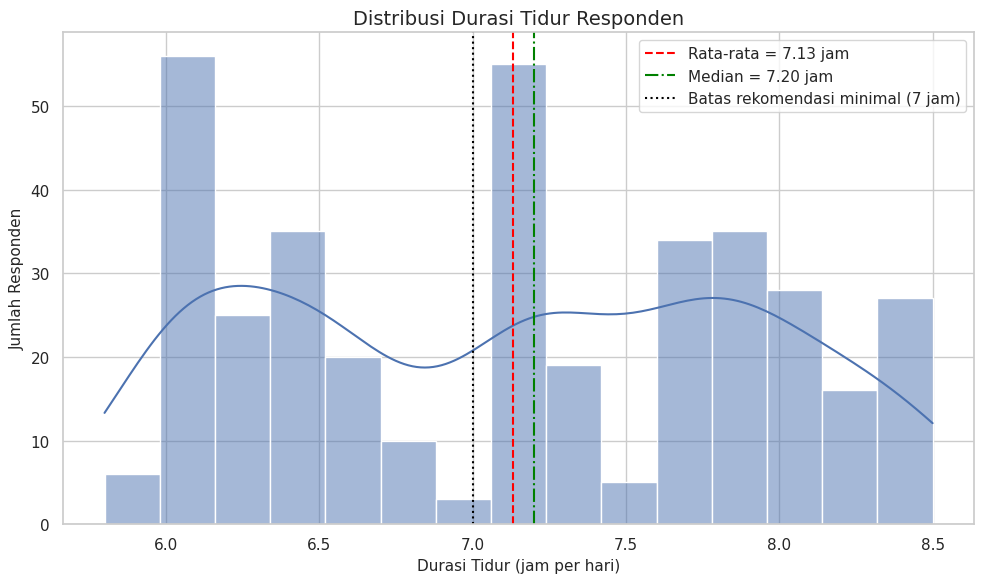

Minimum : 5.8 jam
Maksimum: 8.5 jam
Responden tidur < 7 jam: 155 (41.4%)


In [15]:
data_tidur = df["Sleep Duration"]

plt.figure(figsize=(10, 6))
sns.histplot(data_tidur, bins=15, kde=True, color="#4C72B0")
plt.axvline(data_tidur.mean(), color="red", linestyle="--",
            label=f"Rata-rata = {data_tidur.mean():.2f} jam")
plt.axvline(data_tidur.median(), color="green", linestyle="-.",
            label=f"Median = {data_tidur.median():.2f} jam")
plt.axvline(7, color="black", linestyle=":",
            label="Batas rekomendasi minimal (7 jam)")

plt.title("Distribusi Durasi Tidur Responden")
plt.xlabel("Durasi Tidur (jam per hari)")
plt.ylabel("Jumlah Responden")
plt.legend()
plt.tight_layout()
plt.show()

print("Minimum :", data_tidur.min(), "jam")
print("Maksimum:", data_tidur.max(), "jam")
print("Responden tidur < 7 jam:", (data_tidur < 7).sum(),
      f"({(data_tidur < 7).mean()*100:.1f}%)")

**Interpretasi:**
Durasi tidur responden berkisar antara 5,8 hingga 8,5 jam dengan rata-rata 7,13 jam dan median 7,2 jam. Nilai rata-rata dan median yang berdekatan menunjukkan distribusi yang cukup seimbang. Namun, sebanyak 155 responden (41,4%) tidur kurang dari 7 jam, sehingga hampir separuh responden berada di bawah batas durasi tidur yang umum direkomendasikan bagi orang dewasa. Histogram tampak memiliki beberapa puncak karena durasi tidur tercatat dalam kelipatan 0,1 jam dan banyak responden memiliki nilai yang sama.



### 6.3 Bar Chart — Rata-rata Kualitas Tidur Berdasarkan Pekerjaan

Pekerjaan dengan n < 10 (tidak ditampilkan):
Occupation
Scientist               4
Software Engineer       4
Sales Representative    2
Manager                 1 



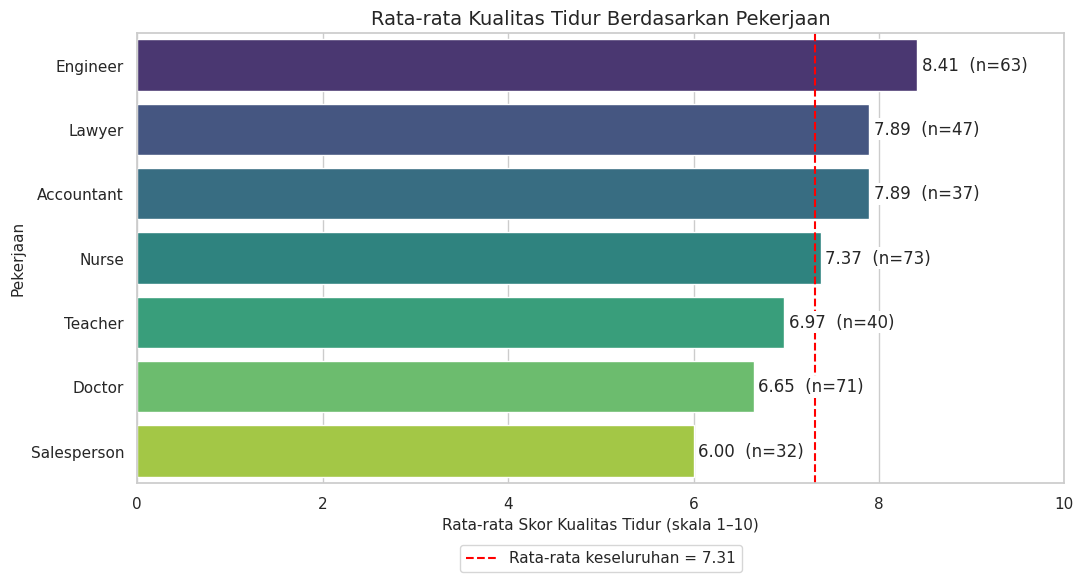

In [16]:
MIN_RESPONDEN = 10   # pekerjaan dengan responden terlalu sedikit tidak ditampilkan

jumlah = df["Occupation"].value_counts()
pekerjaan_valid = jumlah[jumlah >= MIN_RESPONDEN].index
dikeluarkan = jumlah[jumlah < MIN_RESPONDEN]
print("Pekerjaan dengan n <", MIN_RESPONDEN, "(tidak ditampilkan):")
print(dikeluarkan.to_string(), "\n")

rata_kualitas = (
    df[df["Occupation"].isin(pekerjaan_valid)]
    .groupby("Occupation")["Quality of Sleep"]
    .agg(["mean", "count"])
    .sort_values("mean", ascending=False)
)

plt.figure(figsize=(11, 6))
ax = sns.barplot(x=rata_kualitas["mean"], y=rata_kualitas.index,
                 hue=rata_kualitas.index, palette="viridis", legend=False)

for i, (rata, n) in enumerate(zip(rata_kualitas["mean"], rata_kualitas["count"])):
    ax.text(rata + 0.05, i, f"{rata:.2f}  (n={n})", va="center",
            bbox=dict(facecolor="white", edgecolor="none", pad=1.5))

plt.axvline(df["Quality of Sleep"].mean(), color="red", linestyle="--",
            label=f"Rata-rata keseluruhan = {df['Quality of Sleep'].mean():.2f}")
plt.title("Rata-rata Kualitas Tidur Berdasarkan Pekerjaan")
plt.xlabel("Rata-rata Skor Kualitas Tidur (skala 1–10)")
plt.ylabel("Pekerjaan")
plt.xlim(0, 10)
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.tight_layout()
plt.show()

### 6.4 Boxplot — Durasi Tidur Berdasarkan Kategori Stres

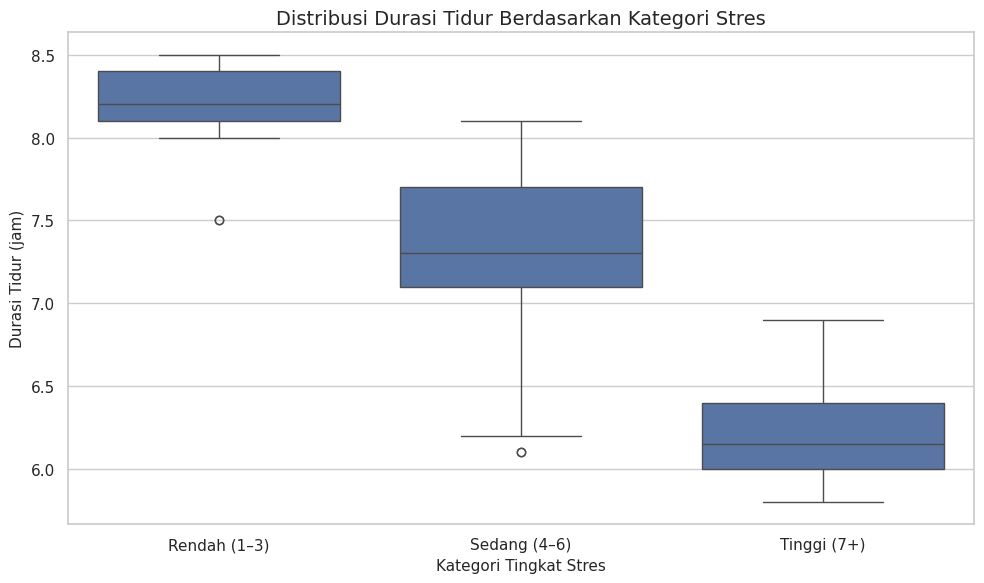

,count,median,mean
Kategori Stres,,,
Rendah (1–3),71,8.20,8.23
Sedang (4–6),183,7.30,7.30
Tinggi (7+),120,6.15,6.22


In [19]:

data_box = df.dropna(
    subset=["Stress Level", "Sleep Duration"]
).copy()

data_box["Kategori Stres"] = pd.cut(
    data_box["Stress Level"],
    bins=[-np.inf, 3, 6, np.inf],
    labels=["Rendah (1–3)", "Sedang (4–6)", "Tinggi (7+)"]
)

plt.figure(figsize=(10, 6))
sns.boxplot(
    data=data_box,
    x="Kategori Stres",
    y="Sleep Duration",
    order=["Rendah (1–3)", "Sedang (4–6)", "Tinggi (7+)"]
)

plt.title("Distribusi Durasi Tidur Berdasarkan Kategori Stres")
plt.xlabel("Kategori Tingkat Stres")
plt.ylabel("Durasi Tidur (jam)")
plt.tight_layout()
plt.show()

display(
    data_box.groupby(
        "Kategori Stres",
        observed=False
    )["Sleep Duration"].agg(
        ["count", "median", "mean"]
    ).round(2)
)


**Interpretasi:**
Semakin tinggi tingkat stres, semakin pendek durasi tidur. Median durasi tidur kelompok stres **rendah** adalah 8,20 jam, kelompok **sedang** 7,30 jam, dan kelompok **tinggi** hanya 6,15 jam. Perbedaan antar kelompok terlihat besar dan kotak boxplot hampir tidak saling tumpang tindih antara kelompok rendah dan tinggi. Pola ini konsisten dengan korelasi negatif yang kuat antara stres dan durasi tidur pada heatmap (r = −0,81).


### 6.5 Scatter Plot — Hubungan Durasi Tidur dan Kualitas Tidur

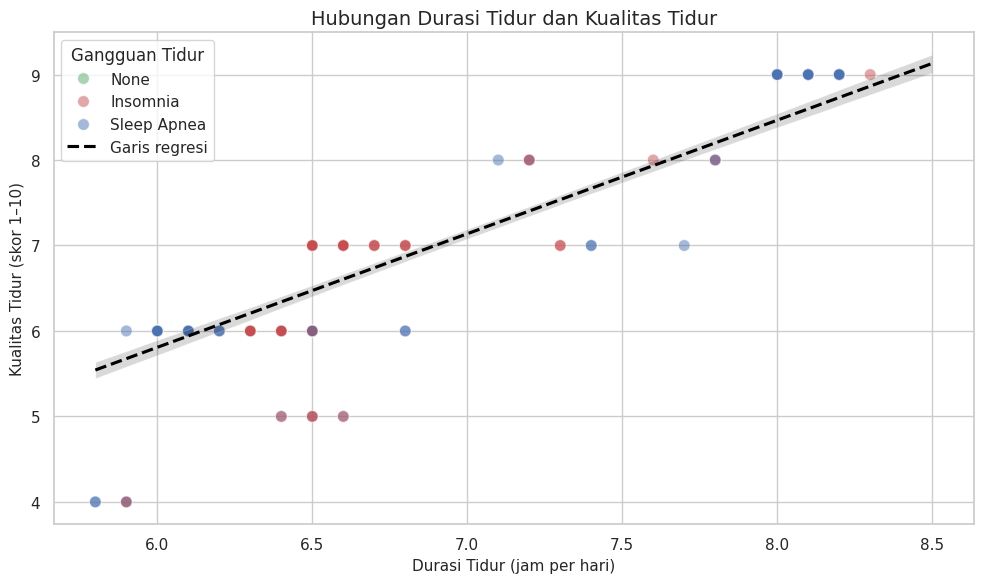

Korelasi Pearson: 0.883


In [24]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df, x="Sleep Duration", y="Quality of Sleep",
    hue="Sleep Disorder", hue_order=["None", "Insomnia", "Sleep Apnea"],
    palette={"None": "#55A868", "Insomnia": "#C44E52", "Sleep Apnea": "#4C72B0"},
    alpha=0.5, s=70
)
sns.regplot(data=df, x="Sleep Duration", y="Quality of Sleep",
            scatter=False, color="black", line_kws={"linestyle": "--"},
            label="Garis regresi")

plt.title("Hubungan Durasi Tidur dan Kualitas Tidur")
plt.xlabel("Durasi Tidur (jam per hari)")
plt.ylabel("Kualitas Tidur (skor 1–10)")
plt.legend(title="Gangguan Tidur")
plt.tight_layout()
plt.show()

korelasi_tidur = df["Sleep Duration"].corr(df["Quality of Sleep"])
print("Korelasi Pearson:", round(korelasi_tidur, 3))

**Interpretasi:**
Titik-titik membentuk pola naik dari kiri bawah ke kanan atas dengan koefisien korelasi Pearson **r = 0,88**, artinya hubungan positif yang sangat kuat: responden yang tidur lebih lama cenderung menilai kualitas tidurnya lebih baik. Responden dengan insomnia (merah) lebih banyak berada di area durasi pendek dan kualitas rendah, sedangkan responden tanpa gangguan (hijau) lebih banyak berada di area kanan atas, meskipun sebagian responden sleep apnea (biru) juga tercatat memiliki kualitas tidur tinggi (skor 9). Karena banyak responden memiliki nilai yang sama, banyak titik saling menumpuk sehingga digunakan transparansi (alpha). Korelasi menunjukkan keterkaitan, bukan bukti sebab-akibat.


### 6.6 Heatmap — Korelasi Antarvariabel Numerik

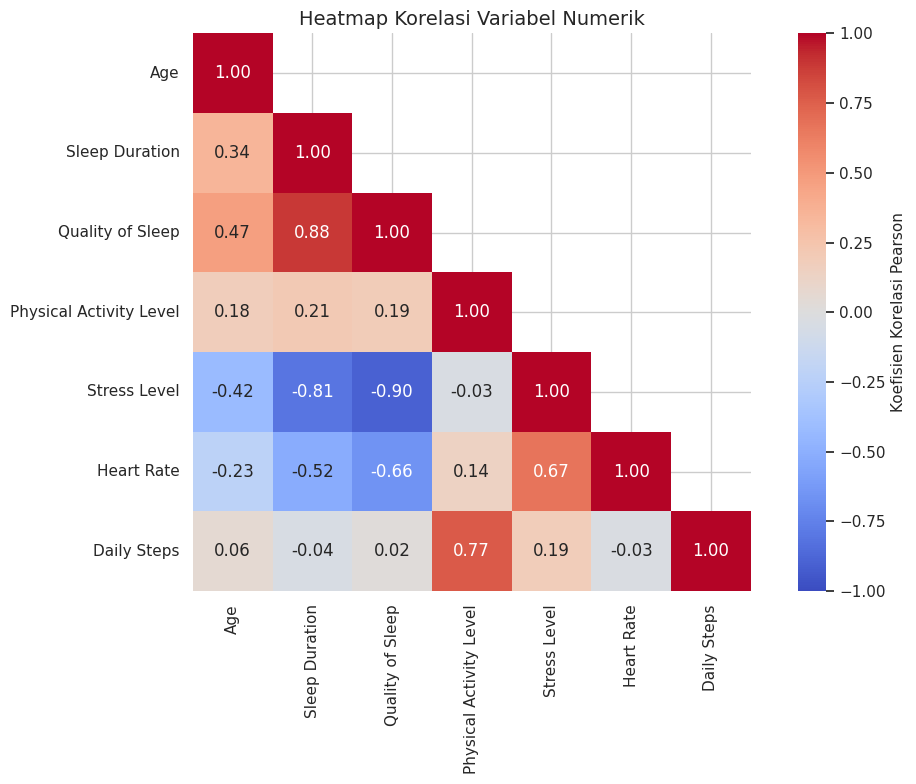

Enam pasangan dengan korelasi absolut terbesar:


Koefisien Korelasi
Quality of Sleep        Stress Level                  -0.899
Sleep Duration          Quality of Sleep               0.883
                        Stress Level                  -0.811
Physical Activity Level Daily Steps                    0.773
Stress Level            Heart Rate                     0.670
Quality of Sleep        Heart Rate                    -0.660

In [21]:
korelasi = df[kolom_numerik].corr()
mask = np.triu(np.ones_like(korelasi, dtype=bool), k=1)

plt.figure(figsize=(11, 8))
sns.heatmap(korelasi, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, square=True,
            cbar_kws={"label": "Koefisien Korelasi Pearson"})
plt.title("Heatmap Korelasi Variabel Numerik")
plt.tight_layout()
plt.show()

atas = korelasi.where(np.triu(np.ones(korelasi.shape), k=1).astype(bool))
pasangan = atas.stack().sort_values(key=abs, ascending=False)
print("Enam pasangan dengan korelasi absolut terbesar:")
display(pasangan.head(6).round(3).to_frame("Koefisien Korelasi"))

**Interpretasi:**
Pasangan variabel dengan hubungan terkuat adalah:
- **Kualitas tidur dan stres** (r = −0,90): semakin tinggi stres, semakin rendah kualitas tidur.
- **Durasi tidur dan kualitas tidur** (r = +0,88): tidur lebih lama berkaitan dengan kualitas tidur lebih baik.
- **Durasi tidur dan stres** (r = −0,81): stres tinggi berkaitan dengan tidur lebih singkat.
- **Aktivitas fisik dan langkah harian** (r = +0,77): wajar, karena keduanya mengukur hal yang berdekatan.
- **Stres dan detak jantung** (r = +0,67) serta **kualitas tidur dan detak jantung** (r = −0,66): detak jantung istirahat yang lebih tinggi cenderung muncul bersama stres tinggi dan kualitas tidur rendah.

Stres muncul sebagai variabel yang paling berkaitan dengan kualitas dan durasi tidur dalam dataset ini.


### 6.7 Bar Chart Berkelompok — Gangguan Tidur Berdasarkan Kategori BMI

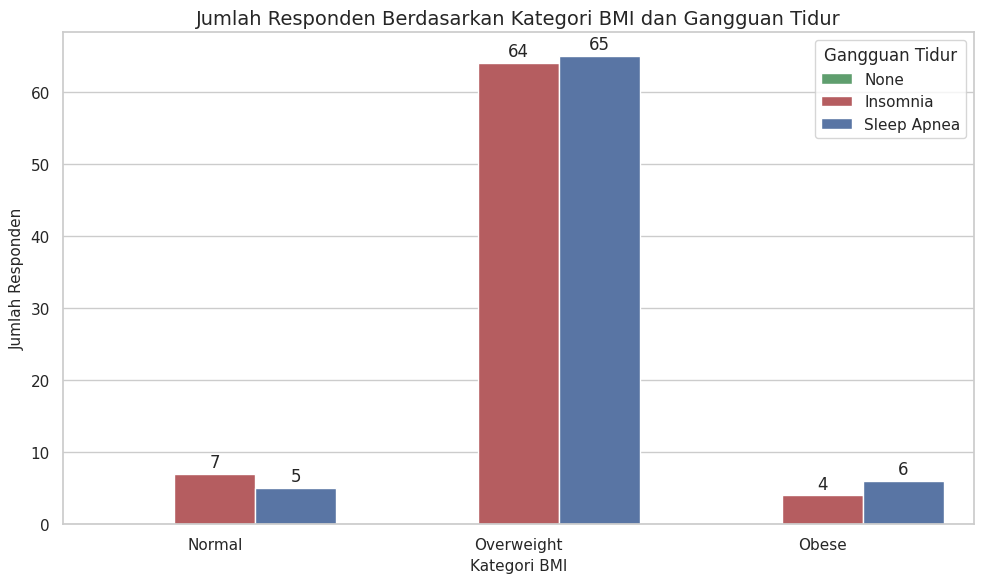

Persentase gangguan tidur per kategori BMI (%):


Sleep Disorder,None,Insomnia,Sleep Apnea
BMI Category,,,
Normal,NaN,58.3,41.7
Overweight,NaN,49.6,50.4
Obese,NaN,40.0,60.0


In [22]:
urutan_bmi = ["Normal", "Overweight", "Obese"]
urutan_gangguan = ["None", "Insomnia", "Sleep Apnea"]

plt.figure(figsize=(10, 6))
ax = sns.countplot(
    data=df, x="BMI Category", hue="Sleep Disorder",
    order=urutan_bmi, hue_order=urutan_gangguan,
    palette={"None": "#55A868", "Insomnia": "#C44E52", "Sleep Apnea": "#4C72B0"}
)
for wadah in ax.containers:
    ax.bar_label(wadah, padding=2)

plt.title("Jumlah Responden Berdasarkan Kategori BMI dan Gangguan Tidur")
plt.xlabel("Kategori BMI")
plt.ylabel("Jumlah Responden")
plt.legend(title="Gangguan Tidur")
plt.tight_layout()
plt.show()

tabel = pd.crosstab(df["BMI Category"], df["Sleep Disorder"]) \
          .reindex(index=urutan_bmi, columns=urutan_gangguan)
print("Persentase gangguan tidur per kategori BMI (%):")
display((tabel.div(tabel.sum(axis=1), axis=0) * 100).round(1))

**Interpretasi:**
Pada kategori BMI **Normal**, sekitar 92,6% responden (200 dari 216) tidak memiliki gangguan tidur. Pada kategori **Overweight**, hanya 12,8% yang tidak memiliki gangguan, sedangkan 43,2% mengalami insomnia dan 43,9% mengalami sleep apnea. Seluruh responden kategori **Obese** (10 orang) memiliki gangguan tidur. Dalam dataset ini, kelebihan berat badan jauh lebih sering muncul bersama gangguan tidur. Perlu diingat bahwa jumlah responden Obese sangat kecil, sehingga persentasenya tidak dapat digeneralisasi, dan ini bukan diagnosis medis.

#**7 — Membuat ringkasan insight otomatis**

#**Ringkasan hasil eksplorasi**

In [12]:

print("=" * 60)
print("RINGKASAN HASIL DATA VISUALIZATION")
print("=" * 60)

print(f"Jumlah responden: {len(df)}")
print(f"Jumlah variabel: {len(df.columns)}")

print("\n1. DURASI TIDUR")
print(f"Rata-rata: {df['Sleep Duration'].mean():.2f} jam")
print(f"Median: {df['Sleep Duration'].median():.2f} jam")

print("\n2. KUALITAS TIDUR")
print(f"Rata-rata skor: {df['Quality of Sleep'].mean():.2f}")
print(f"Skor minimum: {df['Quality of Sleep'].min():.0f}")
print(f"Skor maksimum: {df['Quality of Sleep'].max():.0f}")

print("\n3. TINGKAT STRES")
print(f"Rata-rata: {df['Stress Level'].mean():.2f}")

print("\n4. HUBUNGAN DURASI DAN KUALITAS TIDUR")
print(f"Korelasi Pearson: {korelasi_tidur:.3f}")

print("\n5. NILAI KOSONG")
print(f"Jumlah seluruh sel kosong: {df.isnull().sum().sum()}")

print("\n6. DUPLIKASI")
print(f"Jumlah baris duplikat: {df.duplicated().sum()}")

print("\nCatatan: hasil ini merupakan statistik deskriptif,")
print("bukan bukti hubungan sebab-akibat atau diagnosis medis.")


RINGKASAN HASIL DATA VISUALIZATION
Jumlah responden: 374
Jumlah variabel: 13

1. DURASI TIDUR
Rata-rata: 7.13 jam
Median: 7.20 jam

2. KUALITAS TIDUR
Rata-rata skor: 7.31
Skor minimum: 4
Skor maksimum: 9

3. TINGKAT STRES
Rata-rata: 5.39

4. HUBUNGAN DURASI DAN KUALITAS TIDUR
Korelasi Pearson: 0.883

5. NILAI KOSONG
Jumlah seluruh sel kosong: 219

6. DUPLIKASI
Jumlah baris duplikat: 0

Catatan: hasil ini merupakan statistik deskriptif,
bukan bukti hubungan sebab-akibat atau diagnosis medis.


#**8 — Kesimpulan proyek**


## Kesimpulan

Berdasarkan analisis visualisasi terhadap dataset Sleep Health and Lifestyle (374 responden, 13 variabel), diperoleh beberapa temuan berikut:

1. **Distribusi durasi tidur:** Rata-rata durasi tidur responden adalah **7,13 jam** (median 7,2 jam) dengan rentang 5,8 hingga 8,5 jam. Histogram menunjukkan bahwa sebanyak **41,4%** responden tidur kurang dari 7 jam per hari.

2. **Kualitas tidur berdasarkan pekerjaan:** Kelompok pekerjaan dengan rata-rata kualitas tidur tertinggi adalah **Engineer (8,41)**, sedangkan yang terendah adalah **Salesperson (6,00)**. Pekerjaan dengan kurang dari 10 responden tidak ditampilkan agar rata-rata tidak menyesatkan.

3. **Tingkat stres dan durasi tidur:** Boxplot menunjukkan bahwa semakin tinggi stres, semakin pendek durasi tidur. Median durasi tidur adalah **8,20 jam** pada stres rendah, **7,30 jam** pada stres sedang, dan **6,15 jam** pada stres tinggi.

4. **Hubungan durasi dan kualitas tidur:** Korelasi Pearson sebesar **0,88** menunjukkan hubungan linear **positif yang sangat kuat** antara durasi tidur dan kualitas tidur: responden yang tidur lebih lama cenderung memiliki kualitas tidur lebih baik.

5. **Korelasi antarvariabel:** Heatmap menunjukkan bahwa stres adalah variabel yang paling berkaitan dengan tidur, yaitu berkorelasi negatif dengan kualitas tidur (r = −0,90) dan durasi tidur (r = −0,81). Stres juga berkorelasi positif dengan detak jantung (r = +0,67), sedangkan aktivitas fisik berkorelasi positif dengan langkah harian (r = +0,77).

6. **Kategori gangguan tidur:** Sebanyak **219 responden (58,6%)** tidak memiliki gangguan tidur, **78 responden (20,9%)** mengalami sleep apnea, dan **77 responden (20,6%)** mengalami insomnia. Gangguan tidur jauh lebih sering ditemukan pada responden Overweight (87,2%) dibandingkan responden dengan BMI Normal (7,4%).

## Kesimpulan Akhir

Visualisasi data membantu memahami karakteristik dataset melalui grafik distribusi, perbandingan kelompok, dan hubungan antarvariabel. Histogram, bar chart, boxplot, scatter plot, heatmap, dan line chart memberikan sudut pandang yang berbeda dalam mengeksplorasi data kesehatan tidur dan gaya hidup. Secara keseluruhan, tingkat stres menjadi faktor yang paling menonjol berkaitan dengan durasi dan kualitas tidur.

Hasil analisis bersifat deskriptif dan terbatas pada dataset yang digunakan. Dataset ini memiliki banyak baris dengan profil yang identik dan beberapa kelompok dengan jumlah responden sangat kecil, sehingga temuan perlu diinterpretasikan dengan hati-hati. Hubungan statistik yang ditemukan tidak secara langsung membuktikan hubungan sebab-akibat dan tidak dapat digeneralisasikan ke seluruh populasi.
